# 🌦️ Madar — 24-hour temperature forecast (demo)
**King Khaled International Airport, Riyadh**

This notebook does **not** train anything. It:
1. loads the saved model pipeline from `../models/` (model + train-only scaler + settings)
2. takes the most recent complete input window from the data, in time order
3. forecasts the next 24 hours and shows them on a chart in °C

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras

MODEL_DIR = "../models"
DATA_PATH = "../raw_data/saudi-hourly-weather-data.csv"     # or a newer export with the same columns

def load_pipeline(model_dir=MODEL_DIR):
    with open(f"{model_dir}/pipeline_config.json") as f:
        config = json.load(f)
    return keras.models.load_model(f"{model_dir}/{config['model_file']}"), config

def load_hourly(path, config):
    "Same cleaning as in training: one station, fake values -> NaN, minute-0 readings, gaps not filled."
    df = pd.read_csv(path, sep=";", usecols=["station_name", "observation_date", "air_temperature"])
    df["observation_date"] = pd.to_datetime(df["observation_date"], utc=True).dt.tz_convert(config["timezone"])
    df["temp"] = df["air_temperature"].where(df["air_temperature"] < config["cleaning"]["fake_value_threshold"])
    s = df[(df["station_name"] == config["station"]) & (df["observation_date"].dt.minute == 0)]
    hourly = s.groupby("observation_date")["temp"].mean()
    return hourly.reindex(pd.date_range(hourly.index.min(), hourly.index.max(), freq="h"))

def build_features(index, temp_c, config):
    sc = config["scaler"]
    hour, doy, dow = index.hour.to_numpy(), index.dayofyear.to_numpy(), index.dayofweek.to_numpy()
    cols = {"temp": (np.asarray(temp_c, dtype=float) - sc["mean_C"]) / sc["std_C"],
            "hour_sin": np.sin(2 * np.pi * hour / 24),    "hour_cos": np.cos(2 * np.pi * hour / 24),
            "doy_sin":  np.sin(2 * np.pi * doy / 365.25), "doy_cos":  np.cos(2 * np.pi * doy / 365.25),
            "dow_sin":  np.sin(2 * np.pi * dow / 7),      "dow_cos":  np.cos(2 * np.pi * dow / 7)}
    return np.stack([cols[f] for f in config["features"]], axis=-1)       # same order as in training

def latest_origin(series, config):
    "Last hour that closes a complete input window (no missing hours)."
    full = series.notna().astype(int).rolling(config["window_hours"]).sum() == config["window_hours"]
    return full[full].index[-1]

def forecast(series, origin, model, config):
    W, H, tz = config["window_hours"], config["horizon_hours"], config["timezone"]
    origin = pd.Timestamp(origin)
    origin = origin.tz_localize(tz) if origin.tzinfo is None else origin.tz_convert(tz)
    past = series.loc[origin - pd.Timedelta(hours=W - 1): origin]           # only values up to the origin
    if len(past) != W or past.isna().any():
        raise ValueError(f"need {W} complete hours ending at {origin}")
    z = model.predict(build_features(past.index, past.to_numpy(), config)[None], verbose=0)[0]
    sc = config["scaler"]
    return pd.Series(z * sc["std_C"] + sc["mean_C"],                         # back to °C
                     index=origin + pd.to_timedelta(np.arange(1, H + 1), unit="h"), name="forecast_C")

def show_forecast(series, model, config, origin=None, show_actual=False):
    origin = latest_origin(series, config) if origin is None else pd.Timestamp(origin, tz=config["timezone"])
    fc = forecast(series, origin, model, config)
    past = series.loc[origin - pd.Timedelta(hours=config["window_hours"] - 1): origin]
    actual = series.reindex(fc.index)

    fig, ax = plt.subplots(figsize=(13, 5))
    ax.axvspan(fc.index[0], fc.index[-1], color="#2a78d6", alpha=0.07, lw=0)
    ax.plot(past.index, past.to_numpy(), color="#2b2b2b", lw=2, label=f"last {config['window_hours']} h (input)")
    ax.plot([origin, *fc.index], [past.iloc[-1], *fc.to_numpy()], color="#2a78d6", lw=2.5,
            marker="o", ms=4, markevery=range(1, len(fc) + 1), label="forecast (next 24 h)")
    if show_actual and actual.notna().any():
        ax.plot(actual.index, actual.to_numpy(), color="#2b2b2b", lw=1.5, ls="--", label="actual (if available)")
    lo, hi = min(past.min(), fc.min()), max(past.max(), fc.max())
    ax.set_ylim(lo - 4, hi + 3)                                              # room for the labels
    ax.axvline(origin, color="#8a8a8a", lw=1)
    ax.text(origin, hi + 3, "  now", va="top", color="#5a5a5a")
    for t, label in [(fc.idxmax(), "max"), (fc.idxmin(), "min")]:
        ax.annotate(f"{label} {fc[t]:.1f} °C\n{t:%H:%M}", (t, fc[t]), textcoords="offset points",
                    xytext=(0, 10 if label == "max" else -34), ha="center", fontsize=10, color="#1c5cab")
    ax.set(title=f"Next 24 h temperature — {config['station']} (Riyadh) | forecast made at {origin:%Y-%m-%d %H:%M}",
           ylabel="°C")
    ax.grid(alpha=0.3); ax.legend(loc="upper left")
    plt.tight_layout(); plt.show()
    return fc

2026-10-13 17:56:23.574624: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-13 17:56:23.579584: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-13 17:56:23.593465: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-13 17:56:23.618788: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-13 17:56:23.618827: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-13 17:56:23.634902: I tensorflow/core/platform/cpu_feature_guard.cc:

## Load the saved pipeline and the data

In [2]:
model, config = load_pipeline()
hourly = load_hourly(DATA_PATH, config)
print(f"model: {config['selected_experiment']} | input {config['window_hours']} h → forecast {config['horizon_hours']} h"
      f" | features: {config['features']}")
print(f"data until: {hourly.index.max():%Y-%m-%d %H:%M}")

2026-10-13 17:56:41.015221: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-13 17:56:41.015732: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2251] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


model: lstm_hour_doy | input 72 h → forecast 24 h | features: ['temp', 'hour_sin', 'hour_cos', 'doy_sin', 'doy_cos']
data until: 2025-08-25 00:00


## Forecast

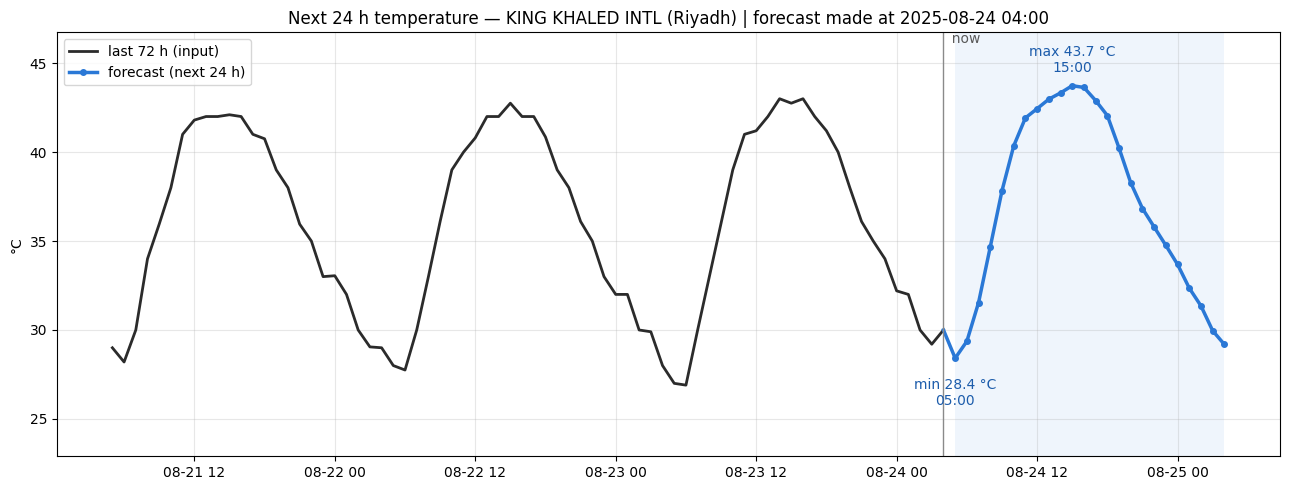

In [3]:
ORIGIN = None      # None = most recent complete 72 h window; or a time such as "2025-08-20 12:00"
fc = show_forecast(hourly, model, config, origin=ORIGIN)